## After Bommer et al. (2025)

In [ ]:
import cdsapi

dataset = "reanalysis-era5-pressure-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["geopotential"],
    "year": [
        "1950", "1951", "1952",
        "1953", "1954", "1955",
        "1956", "1957", "1958",
        "1959", "1960", "1961",
        "1962", "1963", "1964",
        "1965", "1966", "1967",
        "1968", "1969", "1970",
        "1971", "1972", "1973",
        "1974", "1975", "1976",
        "1977", "1978", "1979",
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987"
    ],
    "month": [
        "01", "02", "10",
        "11", "12"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "06:00", "12:00",
        "18:00"
    ],
    "pressure_level": ["500"],
    "grid": "1.0/1.0",
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [80, -90, 20, 30]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()


2026-07-13 17:35:50,700 INFO Request ID is f4c14ccd-3da4-4cfa-8f9e-7231059b18f3
2026-07-13 17:35:50,795 INFO status has been updated to accepted
2026-07-13 17:36:04,641 INFO status has been updated to running


In [ ]:
import cdsapi

dataset = "reanalysis-era5-pressure-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["geopotential"],
    "year": [
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024", "2025"
    ],
    "month": [
        "01", "02", "10",
        "11", "12"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "06:00", "12:00",
        "18:00"
    ],
    "pressure_level": ["500"],
    "grid": "1.0/1.0",
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [80, -90, 20, 30]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()


2026-07-13 17:38:03,820 INFO Request ID is 4782878b-dce4-412d-ba0f-6e95cb2f4bc8
2026-07-13 17:38:03,910 INFO status has been updated to accepted


In [1]:
import xarray as xr
from eofs.xarray import Eof
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
from datetime import datetime, date
from sklearn.cluster import KMeans

In [2]:
ds = xr.load_dataset("z500_50_87.grib", engine="cfgrib")
var_daily1 = ds.z.groupby(ds.z.time.dt.date).mean()

In [3]:
ds = xr.load_dataset("z500_88_25.grib", engine="cfgrib")
var_daily2 = ds.z.groupby(ds.z.time.dt.date).mean()

In [4]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.reset_coords(['number', 'step', 'isobaricInhPa'], drop=True)
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month==2) & (day==29)))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [8]:
var_7dMean = var_daily.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean.time.dt.month
day = var_7dMean.time.dt.day
var_7dMean = var_7dMean.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

In [9]:
var_7dMean_train = var_7dMean.sel(time=slice("1950-07", "2010-06"))
var_7dMean_anom = var_7dMean.groupby('month_day') - var_7dMean_train.groupby('month_day').mean()

In [10]:
month = var_7dMean_anom.time.dt.month
day = var_7dMean_anom.time.dt.day
var_7dMean_anom_djf = var_7dMean_anom.sel(time=((month==12)&(day>3))|(month==1)|(month==2))

In [11]:
annual_clim_raw = var_7dMean_anom_djf.coarsen(time=84).construct(time=("year", "date")).mean('date').rolling(year=30, min_periods=30).mean()
annual_clim = annual_clim_raw.copy()
annual_clim[:30] = annual_clim_raw[29]
annual_clim[30:] = annual_clim_raw[29:-1]

In [12]:
var_7dMean_anom_detrended = var_7dMean_anom.coarsen(time=145).construct(time=("year", "date")) - annual_clim
var_7dMean_anom_detrended = var_7dMean_anom_detrended.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)

In [13]:
month = var_7dMean_anom_detrended.time.dt.month
day = var_7dMean_anom_detrended.time.dt.day
var_7dMean_anom_detrended_djf = var_7dMean_anom_detrended.sel(time=((month==12)&(day>3))|(month==1)|(month==2))

In [14]:
var_7dMean_anom_detrended = var_7dMean_anom_detrended - var_7dMean_anom_detrended_djf.sel(time=slice("1950-07", "2010-06")).mean(dim='time')
var_7dMean_anom_detrended = var_7dMean_anom_detrended.transpose('time', 'latitude', 'longitude')

In [15]:
month = var_7dMean_anom_detrended.time.dt.month
day = var_7dMean_anom_detrended.time.dt.day
var_7dMean_anom_detrended_djf = var_7dMean_anom_detrended.sel(time=((month==12)&(day>3))|(month==1)|(month==2))

In [16]:
var_7dMean_anom_detrended_djf_train = var_7dMean_anom_detrended_djf.sel(time=slice("1950-07", "2010-06"))

In [17]:
coslat = np.cos(np.deg2rad(var_daily.latitude.values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(var_7dMean_anom_detrended_djf_train, weights=wgts)

In [18]:
pcs = solver.pcs(npcs=14)

In [19]:
solver.varianceFraction(neigs=14).sum()

<xarray.DataArray 'variance_fractions' ()> Size: 4B
array(0.9453891, dtype=float32)

In [20]:
kmeans = KMeans(n_clusters=4, n_init=50, random_state=0).fit(pcs)

In [21]:
kmeans.labels_

array([1, 1, 1, ..., 0, 0, 0], shape=(5040,), dtype=int32)

In [22]:
classes = list(kmeans.labels_)
for i in range(4):
    print(f'Number of observations in cluster {i}: {classes.count(i)/len(classes)*100}%')

Number of observations in cluster 0: 22.757936507936506%
Number of observations in cluster 1: 25.416666666666664%
Number of observations in cluster 2: 29.543650793650794%
Number of observations in cluster 3: 22.28174603174603%


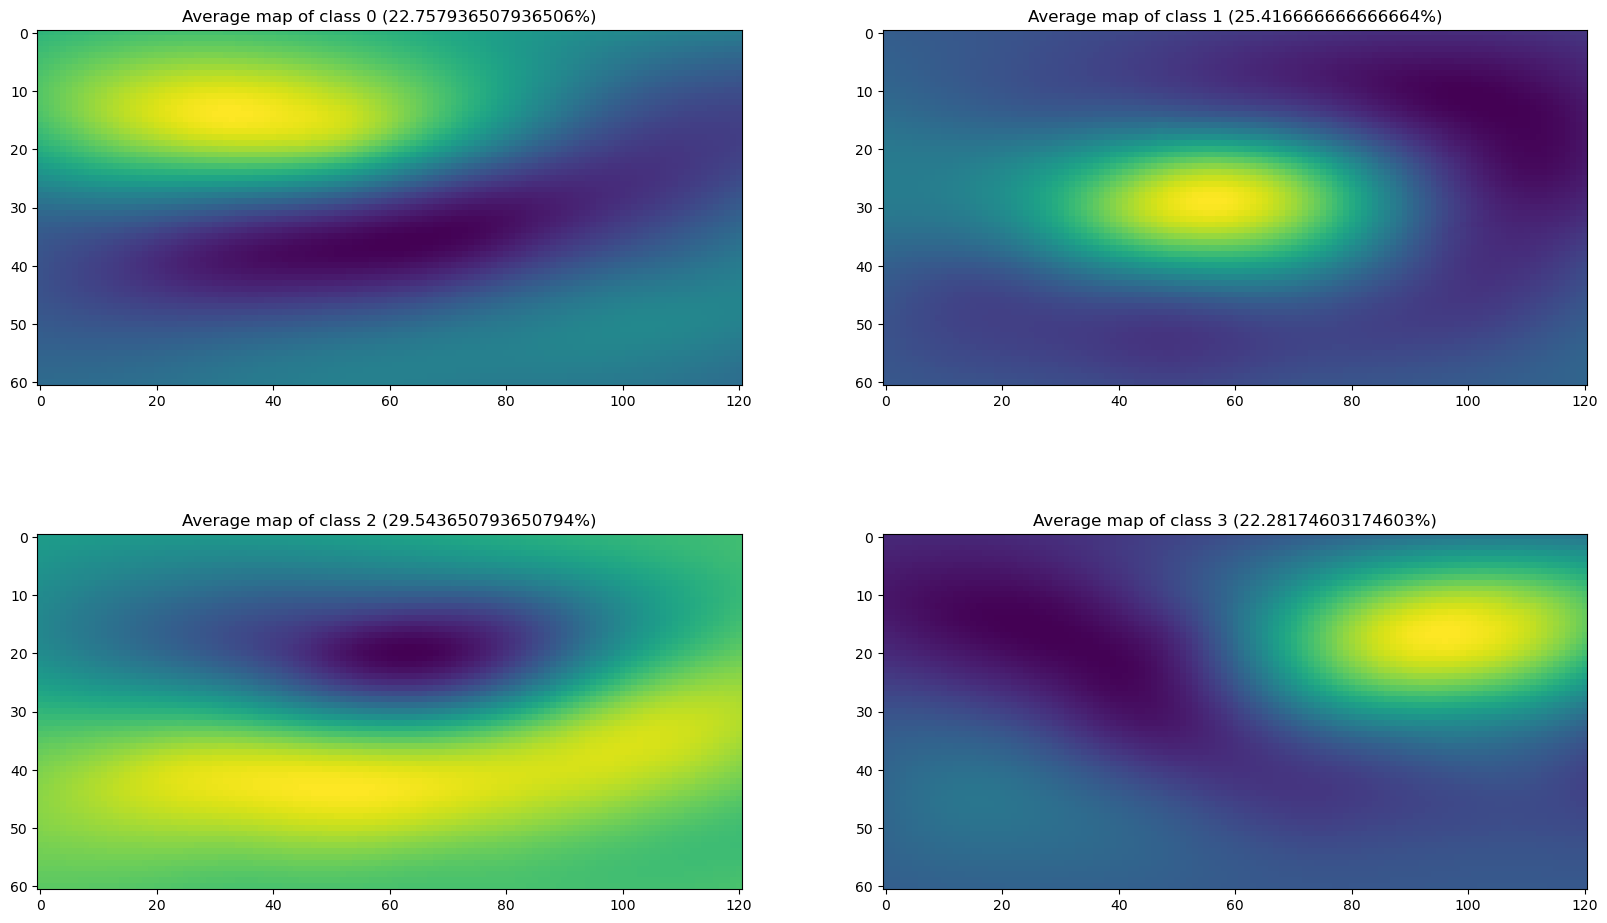

In [23]:
fig, axes = plt.subplots(2,2, figsize=(20,12))
mean_maps = {}
for c, ax in enumerate(axes.flatten()):
    samples_c = [i for i, x in enumerate(classes) if x == c]
    mean_maps[c] = var_7dMean_anom_detrended_djf_train.isel(time=samples_c).mean('time')
    ax.imshow(mean_maps[c])
    ax.set_title(f'Average map of class {c} ({classes.count(c)/len(classes)*100}%)')

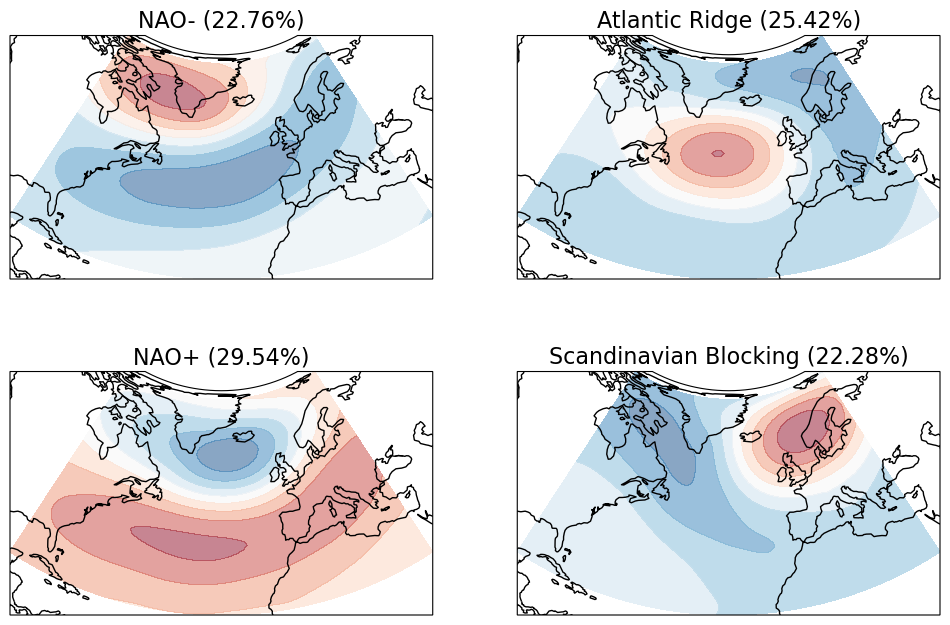

In [24]:
cl_order = [0,1,2,3]
reg ={
        3: 'Scandinavian Blocking',
        0: 'NAO-',
        1: 'Atlantic Ridge',  
        2: 'NAO+',
        }



proj = ccrs.AlbersEqualArea(central_longitude=-30, central_latitude=50)
fig, axes = plt.subplots(2,2,figsize=(12,8), subplot_kw=dict(projection=proj))
for c, data in mean_maps.items():
    
    ax = axes.flatten()[cl_order[c]]
    ax.coastlines()
    ax.contourf(data.longitude.values, data.latitude.values, data.squeeze().values,
                cmap=plt.cm.RdBu_r, transform=ccrs.PlateCarree(), alpha=0.5)
    name_reg = reg[cl_order[c]]
    ax.set_title(f'{name_reg} ({classes.count(cl_order[c])/len(classes)*100:.2f}%)', fontsize=16)

plt.savefig('NAE_regimes.pdf', bbox_inches = 'tight')

In [27]:
pseudo_pcs = solver.projectField(var_7dMean_anom_detrended_djf, neofs=14)

In [28]:
wr_series = kmeans.predict(pseudo_pcs)

In [29]:
classes = list(wr_series[:5040])
for i in range(4):
    print(f'Number of training observations in cluster {i}: {classes.count(i)/len(classes)*100}%')

Number of training observations in cluster 0: 22.757936507936506%
Number of training observations in cluster 1: 25.416666666666664%
Number of training observations in cluster 2: 29.543650793650794%
Number of training observations in cluster 3: 22.28174603174603%


In [30]:
classes = list(wr_series[5040:])
for i in range(4):
    print(f'Number of test observations in cluster {i}: {classes.count(i)/len(classes)*100}%')

Number of test observations in cluster 0: 22.301587301587304%
Number of test observations in cluster 1: 26.190476190476193%
Number of test observations in cluster 2: 33.88888888888889%
Number of test observations in cluster 3: 17.61904761904762%


In [31]:
df_var = var_7dMean_anom_detrended_djf.time.to_dataframe()
df_var['NAE_regime'] = wr_series

In [32]:
df_var = df_var.drop(['month_day'], axis=1)
df_var['time'] = pd.to_datetime(df_var['time'])
df_var = df_var.set_index('time')
df_var

,NAE_regime
time,
1950-12-04,1
1950-12-05,1
1950-12-06,1
1950-12-07,1
1950-12-08,1
...,...
2025-02-21,2
2025-02-22,2
2025-02-23,2


In [33]:
df_var.to_csv('weather_regimes_target.csv')